**Universidad Católica "Nuestra Señora de la Asunción"**

**Facultad de Ciencias y Tecnología**

###**Telecomunicaciones 1**
---



#**Modulation with memory: Sistemas de Modulación Digital con Memoria**

---

**Contenido:**
1. Modulación CPFSK
2. Modulación CPM
3. Modulación MSK

**Objetivos:**
1. Aprender a programar moduladores digitales con memoria
2. Describir mediante gráficos el espectro de señales moduladas
3. Comprender y verificar las ventajas y deventajas de los esquemas programados

In [ ]:
!sudo apt install cm-super dvipng texlive-latex-extra texlive-latex-recommended

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  cm-super-minimal dvisvgm fonts-droid-fallback fonts-lato fonts-lmodern
  fonts-noto-mono fonts-texgyre fonts-urw-base35 ghostscript
  libapache-pom-java libcommons-logging-java libcommons-parent-java
  libfontbox-java libgs9 libgs9-common libidn12 libijs-0.35 libjbig2dec0
  libkpathsea6 libpdfbox-java libptexenc1 libruby3.0 libsynctex2 libteckit0
  libtexlua53 libtexluajit2 libwoff1 libzzip-0-13 lmodern pfb2t1c2pfb
  poppler-data preview-latex-style rake ruby ruby-net-telnet ruby-rubygems
  ruby-webrick ruby-xmlrpc ruby3.0 rubygems-integration t1utils tex-common
  tex-gyre texlive-base texlive-binaries texlive-fonts-recommended
  texlive-latex-base texlive-pictures texlive-plain-generic tipa
  xfonts-encodings xfonts-utils
Suggested packages:
  fonts-noto fonts-freefont-otf | fonts-freefont-ttf ghostscript-x
  libavalon-framework-java l

---
## **1. Modulación CPFSK**

### **1a. Generación de Señales CPFSK:**

\begin{equation}
s(t) = \sqrt{\frac{2ℇ}{T}}\cos\left[2\pi f_c t + \phi(t;\boldsymbol{I})+ \phi_0\right]   
\end{equation}
donde
\begin{equation}
\phi(t;\boldsymbol{𝙄}) = 4\pi T\,f_d\int_{-\infty}^{t} d(\tau)d\tau
\end{equation}        

Simbolos= [0. 1. 2. 3. 1. 1. 2. 2.]
AMPLITUD para cada simbolo=  [-3. -1.  1.  3. -1. -1.  1.  1.]


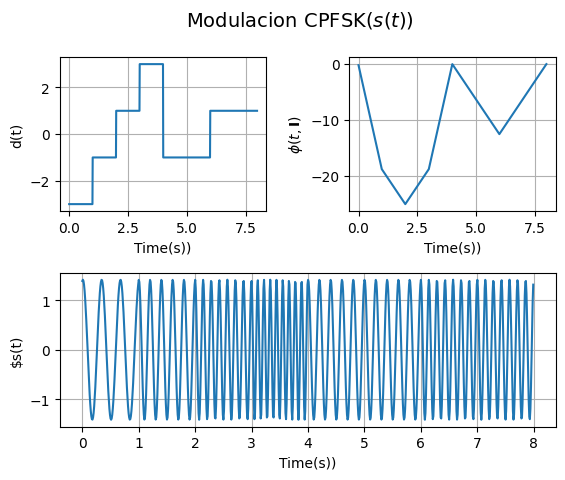

In [ ]:
import matplotlib.pylab as plt
import numpy as np
import math

I=[0,0,0,1,1,0,1,1,0,1,0,1,1,0,1,0]

M=4
Ts=0.01
k= int(math.log(M,2))
Tsym=1
Tsim=int(len(I)/k*Tsym)

E=1
phi_0=0

f_d=1/(2*Tsym)
fc=6

t=np.arange(0,Tsim,Ts)
tsym=np.arange(0,Tsym,Ts)

Am=np.arange(-M+1,M,2)
symbols=np.zeros(int(len(I)/k))
Amp_symbols=np.zeros(int(len(I)/k))

for i in range(0,len(symbols),1):
  for j in range(0,k,1):
    symbols[i]=symbols[i] + I[(i+1)*k-j-1]*math.pow(2,j)
  Amp_symbols[i]=Am[int(symbols[i])]

print("Simbolos=", symbols)
print("AMPLITUD para cada simbolo= ", Amp_symbols)

d=[]

for i in range(0,len(Amp_symbols),1):
  d=np.append(d,Amp_symbols[i]*np.ones(len(tsym)))

plt.subplot(2,2,1)
plt.plot(t,d);
plt.xlabel('Time(s))');
plt.ylabel('d(t)');
plt.grid(True)

phi=4*np.pi*Tsym*Ts*f_d*np.cumsum(d)

plt.subplot(2,2,2)
plt.plot(t,phi);
plt.xlabel('Time(s))');
plt.ylabel('$\phi(t,\mathbf{I})$');
plt.grid(True)

s=math.sqrt((2*E/Tsym))*np.cos(2*np.pi*fc*t+phi+phi_0)
fase=phi+phi_0

plt.subplot2grid((2, 2), (1, 0), colspan=2)
plt.plot(t,s);
plt.xlabel('Time(s))');
plt.ylabel('$s(t)');
plt.grid(True)

plt.subplots_adjust(hspace=0.4,wspace=0.4)
plt.suptitle('Modulacion CPFSK($s(t)$)',fontsize=14)
plt.show()

### **1b. Espectro de CPFSK**

> Agregar bloque entrecomillado




/usr/local/lib/python3.11/dist-packages/scipy/signal/_spectral_py.py:790: UserWarning: nperseg = 4096 is greater than input length  = 800, using nperseg = 800
  freqs, _, Pxy = _spectral_helper(x, y, fs, window, nperseg, noverlap,


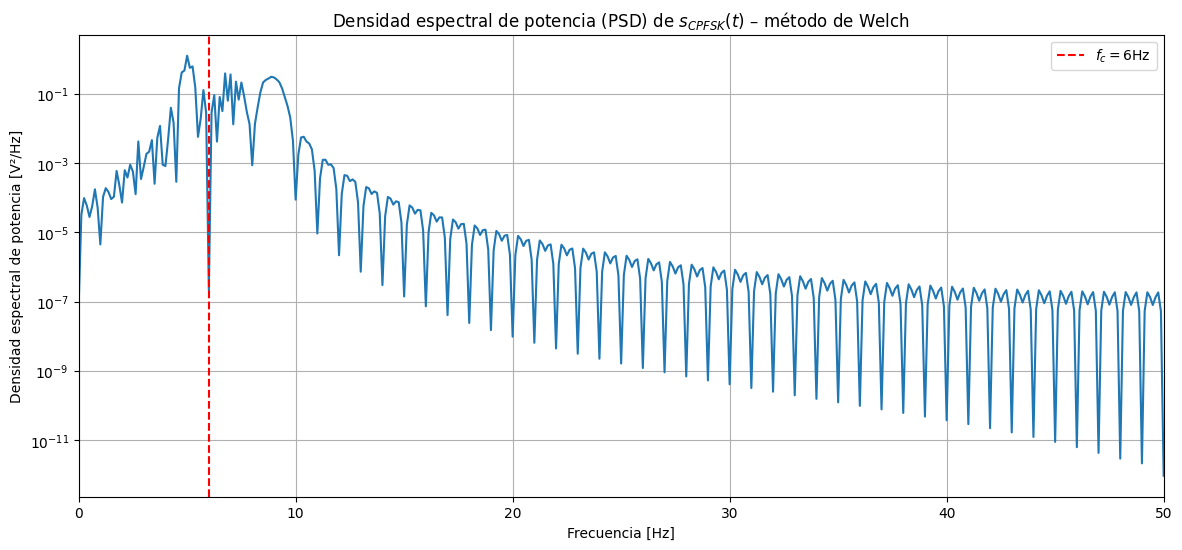

In [ ]:
from scipy.signal import welch
fs = 1/Ts
fwelch,Pxx = welch(s,fs=fs,nperseg=int(2**12),scaling='density')

plt.figure(figsize=(14,6))
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [V²/Hz]")
plt.title("Densidad espectral de potencia (PSD) de $s_{CPFSK}(t)$ – método de Welch")
plt.semilogy(fwelch,Pxx)
plt.xlim([0,fs/2])
plt.grid(True)
plt.axvline(fc,color='r',linestyle = '--',label = f'$f_c={fc}$Hz')
plt.legend()

---
## **2. Modulación CPM**

### **2a. Generación de ondas CPM**

### Caso LRC

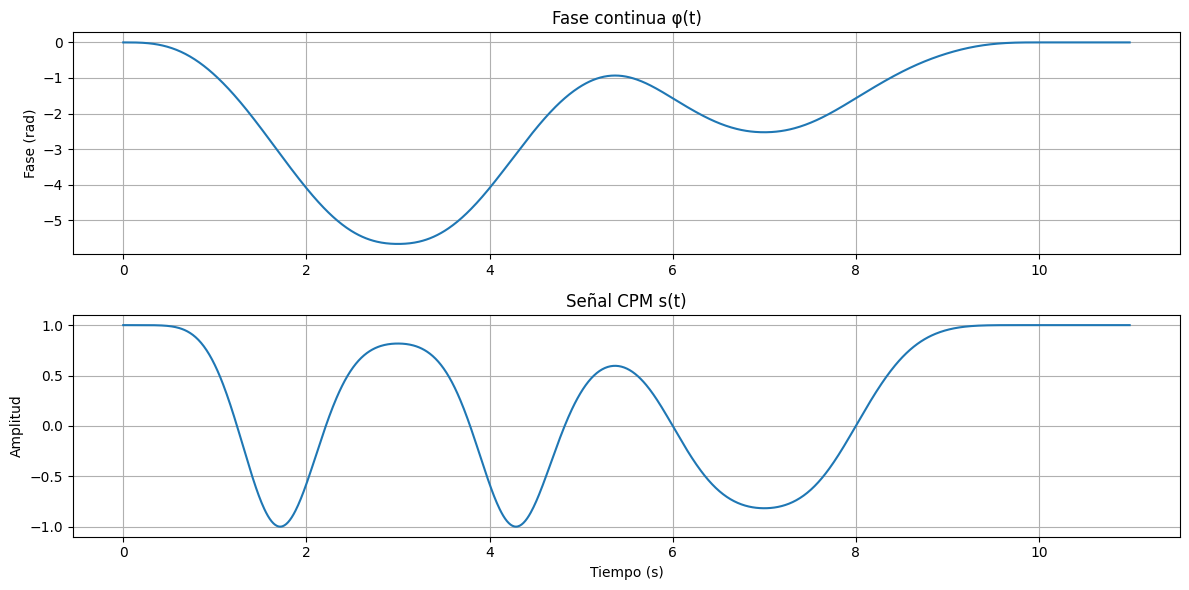

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros básicos
M = 4
h = 0.5
Tsym = 1
L = 3
Ts = 0.01
fc = 0  # portadora opcional

# Secuencia de bits y símbolos
bits = [0,0,0,1,1,0,1,1,0,1,0,1,1,0,1,0]  # 16 bits → 8 símbolos
k = int(np.log2(M))
num_sym = len(bits) // k
symbols = np.zeros(num_sym, dtype=int)

# Mapear bits a enteros y luego a niveles PAM
for i in range(num_sym):
    for j in range(k):
        symbols[i] += bits[i*k + j] << (k - j - 1)
a_n = np.array([-3, -1, 1, 3])[symbols]  # niveles M-PAM

# Tiempo total
t = np.arange(0, (num_sym + L) * Tsym, Ts)
phi = np.zeros_like(t)

# Pulso q(tau) = ∫ g(tau) → función continua LRC
def q_LRC(tau, L, Tsym):
    LT = L * Tsym
    q = np.zeros_like(tau)
    inside = (tau >= 0) & (tau <= LT)
    q[inside] = (tau[inside] / (2 * LT)) - (np.sin(2 * np.pi * tau[inside] / LT)) / (4 * np.pi)
    q[tau > LT] = 0.5
    return q

# Calcular φ(t)
for n, an in enumerate(a_n):
    tn = n * Tsym
    tau = t - tn
    phi += 2 * np.pi * h * an * q_LRC(tau, L, Tsym)

# Señal modulada CPM
s = np.cos(phi + 2 * np.pi * fc * t)  # si fc=0, baseband

# Gráficos
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(t, phi)
plt.title("Fase continua φ(t)")
plt.ylabel("Fase (rad)")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(t, s)
plt.title("Señal CPM s(t)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()
plt.tight_layout()
plt.show()


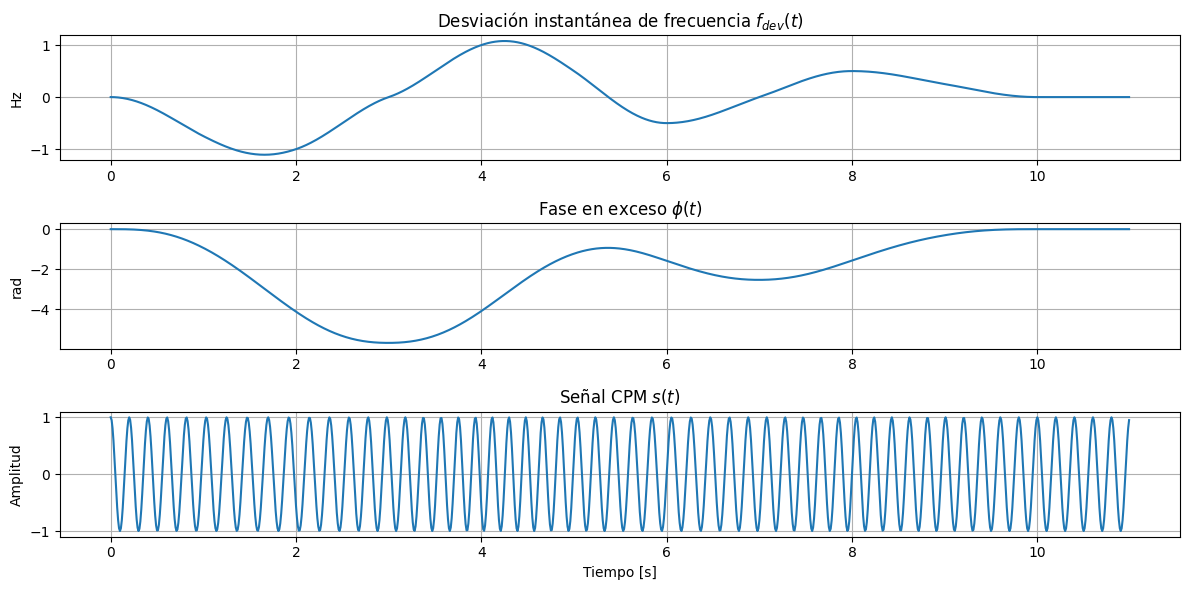

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros CPM
M = 4
h = 0.5
Tsym = 1
L = 3
Ts = 0.01
fc = 5  # Hz
A = 1   # Amplitud

# Generar símbolos
bits = [0,0,0,1,1,0,1,1,0,1,0,1,1,0,1,0]
k = int(np.log2(M))
num_sym = len(bits) // k
symbols = np.zeros(num_sym, dtype=int)
levels = np.array([-3, -1, 1, 3])  # M=4 niveles PAM

for i in range(num_sym):
    for j in range(k):
        symbols[i] += bits[i*k + j] << (k - j - 1)
x_k = levels[symbols]

# Tiempo total
t = np.arange(0, (num_sym + L) * Tsym, Ts)

# h_f(t) LRC (solo tiene soporte [0, LT])
def h_f(tau):
    LT = L * Tsym
    out = np.zeros_like(tau)
    idx = (tau >= 0) & (tau <= LT)
    out[idx] = (1 - np.cos(2 * np.pi * tau[idx] / LT)) / (2 * LT)
    return out

# φ(t) exacta por integración
fdev = np.zeros_like(t)
for k_idx, xk in enumerate(x_k):
    tau = t - k_idx * Tsym
    fdev += xk * h_f(tau)

phi = 2 * np.pi * h * np.cumsum(fdev) * Ts  # integración numérica

# Señal resultante
s = A * np.cos(2 * np.pi * fc * t + phi)

# Graficar resultados
plt.figure(figsize=(12, 6))

plt.subplot(3, 1, 1)
plt.plot(t, fdev)
plt.title("Desviación instantánea de frecuencia $f_{dev}(t)$")
plt.ylabel("Hz")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, phi)
plt.title("Fase en exceso $\\phi(t)$")
plt.ylabel("rad")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, s)
plt.title("Señal CPM $s(t)$")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid()

plt.tight_layout()
plt.show()


### **2b. Espectro de CPM**

Para mejor visualización graficamos en el caso donde la portadora tiene una frecuencia de 25Hz, no como en el caso anterior donde vimos en el caso de 1Hz

/usr/local/lib/python3.11/dist-packages/scipy/signal/_spectral_py.py:790: UserWarning: nperseg = 4096 is greater than input length  = 1100, using nperseg = 1100
  freqs, _, Pxy = _spectral_helper(x, y, fs, window, nperseg, noverlap,


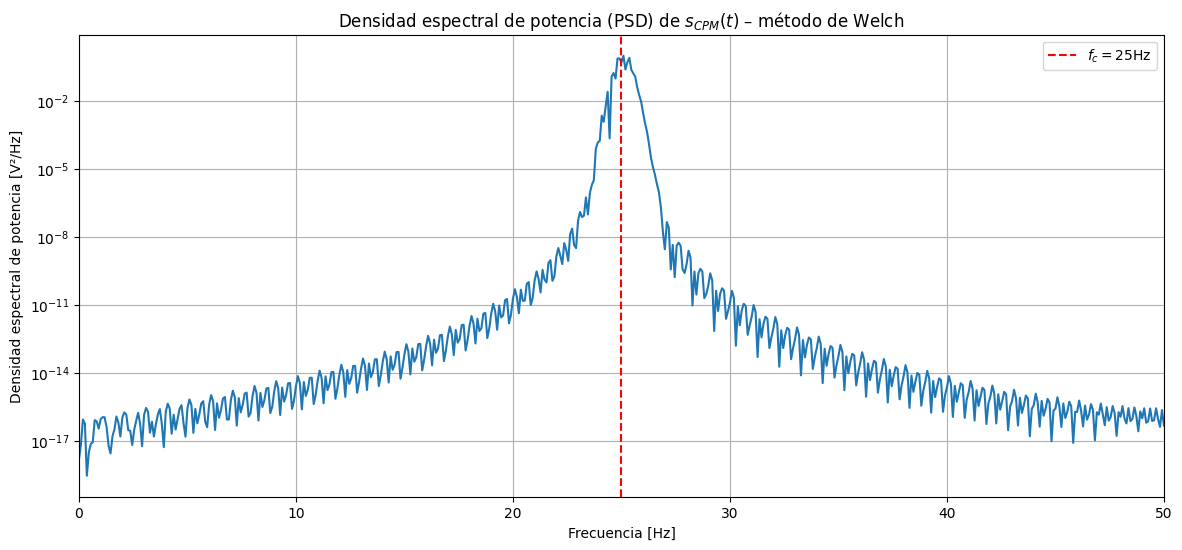

In [19]:
from scipy.signal import welch
fs = 1/Ts
fwelch,Pxx = welch(s,fs=fs,nperseg=int(2**12),scaling='density')

plt.figure(figsize=(14,6))
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [V²/Hz]")
plt.title("Densidad espectral de potencia (PSD) de $s_{CPM}(t)$ – método de Welch")
plt.semilogy(fwelch,Pxx)
plt.xlim([0,fs/2])
plt.grid(True)
plt.axvline(fc,color='r',linestyle = '--',label = f'$f_c={fc}$Hz')
plt.legend()

---
## **3. Modulación MSK**

### **3a. Generación de ondas MSK**

Bits: [0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0]
Amplitud binaria: [-1 -1 -1  1  1 -1  1  1 -1  1 -1  1  1 -1  1 -1]


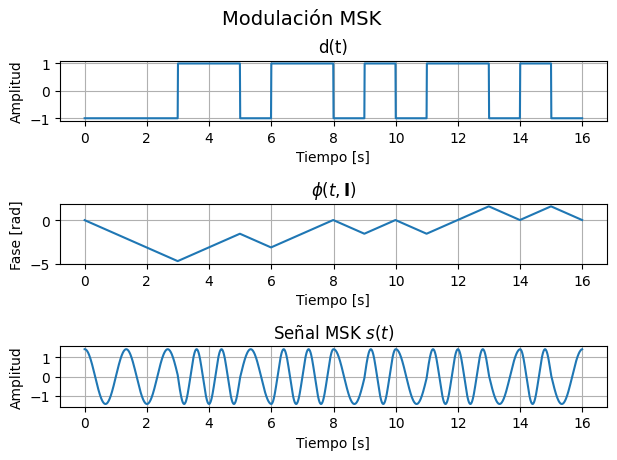

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Parámetros
I = [0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0]
M = 2                         # MSK es binaria
Ts = 0.01                     # Resolución temporal
Tsym = 1                      # Duración del símbolo
k = int(math.log2(M))         # bits por símbolo
Tsim = int(len(I)/k*Tsym)     # Tiempo total de simulación
t = np.arange(0, Tsim, Ts)    # Eje temporal
tsym = np.arange(0, Tsym, Ts) # tiempo por símbolo

E = 1
phi_0 = 0
fc = 1                        # Frecuencia portadora
f_d = 1/(4*Tsym)              # En MSK: h = 0.5 => Δf = 1/(2T) => f_d = Δf/2 = 1/(4T)

# Mapeo binario a ±1
Amp_symbols = 2*np.array(I) - 1
print("Bits:", I)
print("Amplitud binaria:", Amp_symbols)

# Onda d(t)
d = np.repeat(Amp_symbols, len(tsym))
plt.subplot(3, 1, 1)
plt.plot(t, d)
plt.title('d(t)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True)

# Fase acumulada φ(t;I)
phi = 2 * np.pi * f_d * Ts * np.cumsum(d)
plt.subplot(3, 1, 2)
plt.plot(t, phi)
plt.title(r'$\phi(t,\mathbf{I})$')
plt.xlabel('Tiempo [s]')
plt.ylabel('Fase [rad]')
plt.grid(True)

# Señal modulada s(t)
s = np.sqrt(2 * E / Tsym) * np.cos(2 * np.pi * fc * t + phi + phi_0)
plt.subplot(3, 1, 3)
plt.plot(t, s)
plt.title('Señal MSK $s(t)$')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.suptitle('Modulación MSK', fontsize=14)
plt.show()


### **3b. Espectro de CPM**

Para mejor visualización graficamos en el caso donde la portadora tiene una frecuencia de 25Hz, no como en el caso anterior donde vimos en el caso de 1Hz

/usr/local/lib/python3.11/dist-packages/scipy/signal/_spectral_py.py:790: UserWarning: nperseg = 4096 is greater than input length  = 1600, using nperseg = 1600
  freqs, _, Pxy = _spectral_helper(x, y, fs, window, nperseg, noverlap,


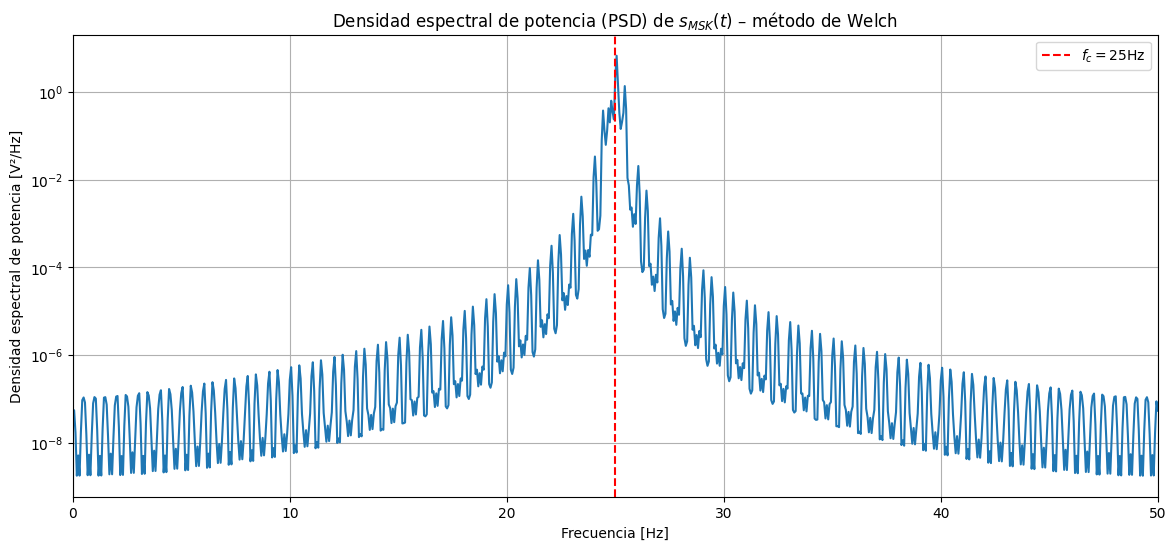

In [16]:
from scipy.signal import welch
fs = 1/Ts
fwelch,Pxx = welch(s,fs=fs,nperseg=int(2**12),scaling='density')

plt.figure(figsize=(14,6))
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Densidad espectral de potencia [V²/Hz]")
plt.title("Densidad espectral de potencia (PSD) de $s_{MSK}(t)$ – método de Welch")
plt.semilogy(fwelch,Pxx)
plt.xlim([0,fs/2])
plt.grid(True)
plt.axvline(fc,color='r',linestyle = '--',label = f'$f_c={fc}$Hz')
plt.legend()

##Conclusiones##

1. La modulación CPFSK permite observar una clara continuidad de fase, propiedad fundamental de los esquemas con memoria. Esta continuidad se logra mediante la integración acumulativa de la señal
$d(t)$, lo que evita saltos abruptos de fase al cambiar de símbolo. En el dominio espectral, la señal presenta un espectro centrado en la portadora con lóbulos laterales típicos de modulaciones digitales. Sin embargo, el ancho de banda resulta considerablemente mayor en comparación con otras variantes de fase continua, debido a las transiciones abruptas entre símbolos que introducen componentes espectrales significativas que tardan en atenuarse.

2. En el caso de la modulación CPM con pulso LRC (Linear Raised Cosine), se mantiene la continuidad de fase, pero con una mejora sustancial en el espectro. Esto se debe a que la función de fase $q(t)$ se suaviza mediante un coseno elevado, lo cual reduce drásticamente la energía en los lóbulos laterales. Si bien en el dominio temporal la señal no se distingue fácilmente de las demás variantes de CPM, su densidad espectral de potencia (PSD) evidencia una notoria mejora, posicionándola como la opción más eficiente desde el punto de vista espectral.

3. La modulación MSK representa una mejora frente a CPFSK al reducir el ancho de banda, manteniendo una implementación sencilla basada en pulsos. Esta eficiencia espectral se debe a que utiliza un índice de modulación $h=0.5$, el valor mínimo que permite ortogonalidad entre símbolos consecutivos. Esto implica que en cada transición se acumula una cantidad de fase moderada, logrando un equilibrio entre compacidad espectral y simplicidad estructural.